# Classificação supervisionada v4 com SMILE Random Forest

Cada amostra resume um polígono com médias Landsat 8 e NDVI MODIS mensal. A inferência usa os mesmos preditores em uma grade de 500 m.

In [1]:
import ee

from repository_ee import (
    Exports,
    MODIS_13_Q1,
    GeometryUtils,
    Landsat8,
    MapLayers,
    Models,
    PeriodoAgricola,
    initialize_earth_engine,
)

## 1. Inicialização e parâmetros gerais

A AOI e o ano precisam ser os mesmos usados na criação das amostras.

In [2]:
initialize_earth_engine(use_eerepr=True)

ANO = 2025
ESCALA = 30
SEED = 42
FRACAO_TREINO = 0.70
PROPRIEDADE_CLASSE = "landcover"

COORDS_TOCANTINS = [
    [-48.46995289774661, -10.859497023647087],
    [-47.84922535868411, -10.859497023647087],
    [-47.84922535868411, -10.362094203375317],
    [-48.46995289774661, -10.362094203375317],
    [-48.46995289774661, -10.859497023647087],
]

aoi = GeometryUtils.polygon(COORDS_TOCANTINS)
periodo = PeriodoAgricola.tocantins(ANO)

## 2. Imagem e variáveis preditoras

Esta etapa prepara o feature space Landsat e os nomes das colunas mensais de NDVI lidas da Wide Table.

In [ ]:
landsat = Landsat8.collection(aoi, periodo)
feature_space = Landsat8.feature_space(landsat, aoi, periodo)

colunas_ndvi = [f"ndvi_mean_mean_{ANO}-{mes:02d}-01" for mes in range(1, 13)]
bandas_preditoras = feature_space.bandNames().cat(colunas_ndvi)
ESCALA_GRADE = 500
projecao_grade = ee.Projection("EPSG:32722").atScale(ESCALA_GRADE)

## 3. Carregamento e rotulagem dos polígonos

Floresta e Cerrado compartilham o rótulo de vegetação nativa do asset de reserva florestal. A área urbana recebe um rótulo próprio.

In [ ]:
RAIZ_ASSETS = "projects/lateral-spirit-514212-j0/assets"
CLASSES = {
    0: ("Floresta/Cerrado", "tocantins_2025_RESERVA_FLORESTAL", "006400"),
    1: ("Agricultura", "tocantins_2025_AGRICULTURA", "ffcc00"),
    2: ("Água", "tocantins_2025_AGUA", "0000ff"),
    3: ("Área urbana", "tocantins_2025_RESERVA_URBANA", "d73027"),
    4: ("Pastagem", "Amostras_PASTAGEM_WIDE_2025", "7cb342"),
}
ORDEM_CLASSES = list(CLASSES)


def carregar_poligonos(classe: int, nome: str, asset: str) -> ee.FeatureCollection:
    """Carrega o asset e atribui o rótulo numérico."""
    return (
        ee.FeatureCollection(f"{RAIZ_ASSETS}/{asset}")
        .filterBounds(aoi)
        .map(lambda feicao: feicao.set({
            PROPRIEDADE_CLASSE: classe,
            "classe_nome": nome,
        }))
    )


poligonos_por_classe = {
    classe: carregar_poligonos(classe, nome, asset)
    for classe, (nome, asset, _) in CLASSES.items()
}

## 4. Separação dos polígonos de treino e validação

O sorteio é feito por classe. Cada polígono inteiro pertence a um conjunto.

In [5]:
poligonos_treino = ee.FeatureCollection([])
poligonos_validacao = ee.FeatureCollection([])
for classe, colecao in poligonos_por_classe.items():
    com_split = colecao.randomColumn(columnName="split", seed=SEED + classe)
    poligonos_treino = poligonos_treino.merge(
        com_split.filter(ee.Filter.lt("split", FRACAO_TREINO))
    )
    poligonos_validacao = poligonos_validacao.merge(
        com_split.filter(ee.Filter.gte("split", FRACAO_TREINO))
    )

In [6]:
mapa_poligonos = MapLayers.create(aoi, zoom=9)
mapa_poligonos.addLayer(
    poligonos_treino, {"color": "1a9850"}, "Polígonos — treinamento"
)
mapa_poligonos.addLayer(
    poligonos_validacao, {"color": "d73027"}, "Polígonos — validação"
)
mapa_poligonos

Map(center=[-10.61088033468291, -48.15958912821537], controls=(WidgetControl(options=['position', 'transparent…

## 5. Extração de preditores por polígono

O treino e a validação leem as 12 médias mensais de NDVI diretamente do asset `zonal_stats_wide_2025`, com correspondência pelo campo `id`. A geometria e o rótulo vêm dos polígonos de amostra. Depois da junção, o notebook acrescenta as médias das bandas Landsat.

Cada classe precisa de polígonos com os mesmos IDs na Wide Table e nos assets de amostras, com preditores completos tanto no treino quanto na validação.

In [ ]:
def calcular_medias_landsat(unidades: ee.FeatureCollection) -> ee.FeatureCollection:
    """Acrescenta a média de cada banda Landsat e retém linhas completas."""
    return feature_space.reduceRegions(
        collection=unidades,
        reducer=ee.Reducer.mean(),
        crs=projecao_grade,
        scale=ESCALA,
        tileScale=2,
    ).filter(ee.Filter.notNull(bandas_preditoras))


ASSET_WIDE_NDVI = f"{RAIZ_ASSETS}/zonal_stats_wide_2025"
wide_ndvi = ee.FeatureCollection(ASSET_WIDE_NDVI).filter(
    ee.Filter.notNull(["id", *colunas_ndvi])
)


def copiar_ndvi_da_wide(poligono: ee.Feature) -> ee.Feature:
    """Copia apenas as médias mensais e mantém a geometria e o rótulo originais."""
    linha_wide = ee.Feature(poligono.get("linha_wide"))
    propriedades = poligono.propertyNames().remove("linha_wide")
    return poligono.select(propriedades).set(linha_wide.toDictionary(colunas_ndvi))


def preparar_amostras(poligonos: ee.FeatureCollection) -> ee.FeatureCollection:
    """Usa somente amostras com as 12 médias mensais prontas na Wide Table."""
    poligonos_com_ndvi = ee.FeatureCollection(
        ee.Join.saveFirst(matchKey="linha_wide").apply(
            primary=poligonos.filter(ee.Filter.notNull(["id"])),
            secondary=wide_ndvi,
            condition=ee.Filter.equals(leftField="id", rightField="id"),
        )
    )
    return calcular_medias_landsat(poligonos_com_ndvi.map(copiar_ndvi_da_wide))


amostras_treino = preparar_amostras(poligonos_treino)
amostras_validacao = preparar_amostras(poligonos_validacao)
for nome, conjunto in (
    ("treinamento", amostras_treino),
    ("validação", amostras_validacao),
):
    distribuicao = Models.class_distribution(conjunto, PROPRIEDADE_CLASSE).getInfo()
    faltantes = [CLASSES[c][0] for c in ORDEM_CLASSES if str(c) not in distribuicao]
    if faltantes:
        raise ValueError(
            f"Sem polígonos com preditores completos em {nome}: {', '.join(faltantes)}. "
            "Confira os IDs e as 12 colunas mensais na Wide Table e a cobertura Landsat."
        )
    print(f"Amostras de {nome}:", distribuicao)

## 6. Treinamento do SMILE Random Forest

A criação e o treinamento do classificador passam pela classe `Models`. `max_nodes` controla o tamanho máximo da árvore e `min_leaf_population` evita folhas sustentadas por pouquíssimos pixels.

In [8]:
modelo_rf = Models.train(
    samples=amostras_treino,
    input_properties=bandas_preditoras,
    class_property=PROPRIEDADE_CLASSE,
    algorithm="rf",
    classifier_parameters={
        "number_of_trees": 100,
        "variables_per_split": 5,
        "bag_fraction": 0.8,
        "max_nodes": 100,
        "min_leaf_population": 10,
        
    },
)

modelo_rf.explain()

## 7. Classificação da imagem

Os compostos MODIS mensais são calculados aqui para obter NDVI nas células de 500 m da grade de inferência. Cada célula recebe os mesmos tipos de média Landsat e NDVI usados no treino. A classe prevista representa a célula inteira.

In [ ]:
modis_ndvi = (
    ee.ImageCollection(MODIS_13_Q1)
    .filterBounds(aoi)
    .filterDate(periodo.inicio_anual, periodo.fim_anual)
    .select("NDVI")
)
projecao_modis = modis_ndvi.first().projection()
inicio_ano = ee.Date(periodo.inicio_anual)
compostos_ndvi = []
for indice, coluna in enumerate(colunas_ndvi):
    inicio = inicio_ano.advance(indice, "month")
    fim = inicio.advance(1, "month")
    composto = modis_ndvi.filterDate(inicio, fim).mean()
    compostos_ndvi.append(composto.rename(coluna))
ndvi_mensal = ee.Image.cat(compostos_ndvi)


def calcular_medias_ndvi(unidades: ee.FeatureCollection) -> ee.FeatureCollection:
    """Calcula médias mensais na projeção nativa MODIS."""
    return ndvi_mensal.reduceRegions(
        collection=unidades,
        reducer=ee.Reducer.mean(),
        crs=projecao_modis,
        scale=projecao_modis.nominalScale(),
        tileScale=2,
    )


grade = aoi.coveringGrid(projecao_grade)
grade_com_preditores = calcular_medias_landsat(calcular_medias_ndvi(grade))


def rasterizar_coluna(coluna: ee.String) -> ee.Image:
    """Cria uma banda com a média de cada célula."""
    coluna = ee.String(coluna)
    return grade_com_preditores.reduceToImage(
        properties=ee.List([coluna]),
        reducer=ee.Reducer.first(),
    ).rename(coluna)


imagem_preditores = (
    ee.ImageCollection.fromImages(bandas_preditoras.map(rasterizar_coluna))
    .toBands()
    .rename(bandas_preditoras)
    .setDefaultProjection(projecao_grade)
)
classificacao_rf = Models.classify_image(
    feature_space=imagem_preditores,
    classifier=modelo_rf,
    input_properties=bandas_preditoras,
    output_band=PROPRIEDADE_CLASSE,
).clip(aoi)

VIS_RF = {
    "bands": [PROPRIEDADE_CLASSE],
    "min": min(ORDEM_CLASSES),
    "max": max(ORDEM_CLASSES),
    "palette": [CLASSES[classe][2] for classe in ORDEM_CLASSES],
}
mapa = MapLayers.create(aoi, zoom=9)
MapLayers.add_rgb(mapa, feature_space, "Landsat — RGB")
mapa.addLayer(classificacao_rf, VIS_RF, "Random Forest v4")
for classe, (nome, _, cor) in CLASSES.items():
    mapa.addLayer(poligonos_por_classe[classe], {"color": cor}, f"Polígonos — {nome}")
mapa

## 8. Avaliação do treinamento e validação independente

A matriz de validação mede o desempenho nos polígonos reservados. A transferência para células de 500 m depende de quanto elas se parecem com os polígonos amostrados.

In [10]:
metricas_treino = Models.training_metrics(modelo_rf)
metricas_validacao = Models.validation_metrics(
    classifier=modelo_rf,
    validation_samples=amostras_validacao,
    class_property=PROPRIEDADE_CLASSE,
    prediction_property="classification",
    class_order=ORDEM_CLASSES,
)
print("#### RANDOM FOREST ACURACY ####")
print("Matriz de confusão — treinamento:")
print(metricas_treino["confusion_matrix"].getInfo())
print("Acurácia de treinamento:", metricas_treino["accuracy"].getInfo())

print("\nMatriz de confusão — validação:")
print(metricas_validacao["confusion_matrix"].getInfo())
print("Acurácia de validação:", metricas_validacao["accuracy"].getInfo())
print("Kappa de validação:", metricas_validacao["kappa"].getInfo())
print("Acurácia do produtor:", metricas_validacao["producers_accuracy"].getInfo())
print("Acurácia do consumidor:", metricas_validacao["consumers_accuracy"].getInfo())

#### RANDOM FOREST ACURACY ####
Matriz de confusão — treinamento:
[[12, 0, 0, 0, 0], [0, 15, 0, 0, 0], [9, 0, 0, 0, 0], [0, 0, 0, 9, 2], [0, 3, 0, 2, 26]]
Acurácia de treinamento: 0.7948717948717948

Matriz de confusão — validação:
[[5, 0, 0, 0, 0], [0, 5, 0, 0, 2], [3, 0, 0, 0, 0], [0, 0, 0, 1, 0], [1, 2, 0, 1, 11]]
Acurácia de validação: 0.7096774193548387
Kappa de validação: 0.5835820895522389
Acurácia do produtor: [[1], [0.7142857142857143], [0], [1], [0.7333333333333333]]
Acurácia do consumidor: [[0.5555555555555556, 0.7142857142857143, 0, 0.5, 0.8461538461538461]]


## 9. Visualização das amostras no espaço PCA

O gráfico projeta as amostras de validação em dois componentes principais. O visualizador padroniza os mesmos preditores Landsat e NDVI usados no treino e usa os nomes de classe definidos em `CLASSES`.

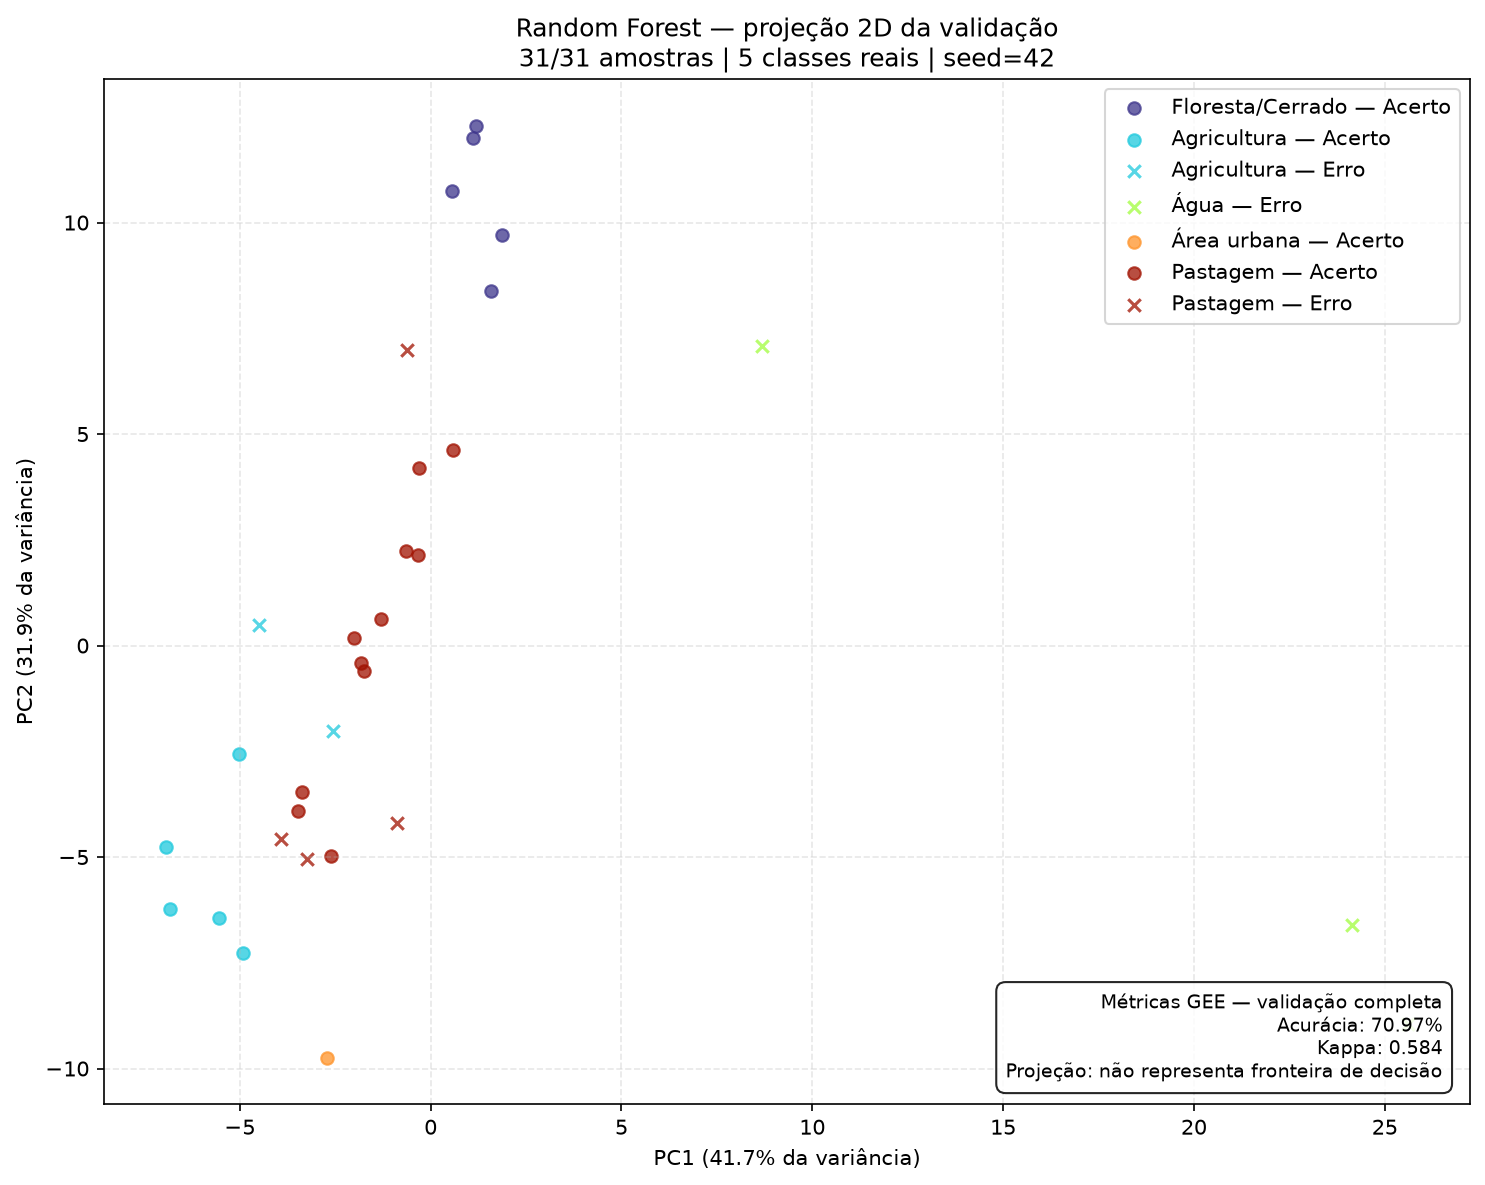

Gráfico salvo em: plots\random-forest-v4-validation.png


In [11]:
from repository_ee import Visualizer

# Pontos limitados para visualização; métricas GEE da validação completa.
resultado_visualizacao = Visualizer.plot_random_forest_classification(
    validation_metrics=metricas_validacao,
    feature_columns=bandas_preditoras,
    label_property=PROPRIEDADE_CLASSE,
    prediction_property="classification",
    class_names={classe: dados[0] for classe, dados in CLASSES.items()},
    projection="pca",
    standardize=True,
    output_path="plots/random-forest-v4-validation.png",
    max_samples=3000,
    seed=SEED,
    figsize=(10, 8),
    dpi=150,
    show=True,
)

print("Gráfico salvo em:", resultado_visualizacao["output_path"])

## 10. Exportação da imagem classificada

Edite `ASSET_CLASSIFICACAO_V4` para escolher o destino no Earth Engine. A tarefa exporta a área de estudo na resolução da grade de inferência e usa a classe mais frequente nas visualizações em escalas menores. Descomente `tarefa_classificacao_v4.start()` para iniciar.

In [12]:
ASSET_CLASSIFICACAO_V4 = f"{RAIZ_ASSETS}/tocantins_{ANO}_classification_v4"

tarefa_classificacao_v4 = Exports.image_to_assets(
    image=classificacao_rf,
    asset_id=ASSET_CLASSIFICACAO_V4,
    description=f"tocantins_{ANO}_classification_v4",
    region=aoi,
    scale=ESCALA_GRADE,
    pyramiding_policy={".default": "mode"},
)
tarefa_classificacao_v4.start()

## Observação metodológica

Cada polígono fornece uma amostra. As cinco classes precisam aparecer nos conjuntos de treino e validação com preditores completos.